# Ensemble Learning Assignment: Forecasting Pettah Wholesale Beans Prices

**Prakasan R. (224152U)**

**Problem:** predict next week's average wholesale price of beans at Pettah market, so farmers, traders and small eateries can plan when to buy and sell.

**Data:** Central Bank of Sri Lanka, Daily Price Report, via Macro Lab (macrolab.lk), Aug 2016 to Nov 2026.


## Step 1: Load and understand the data

Load the Macro Lab file. `comment="#"` skips the 6 note lines at the top of the file, and `parse_dates` turns `period` into real dates so the days can be grouped into weeks later.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("dataset/daily-prices-d.csv", comment="#", parse_dates=["period"])
df.shape

(2470, 263)

### Choosing the columns

The file has 262 price series; only four are kept:
- `beans_pettah`: the **target** (Pettah wholesale beans, Rs/kg).
- `beans_dambulla`: Dambulla is a large wholesale centre closer to the farms, so its price can move before Pettah's.
- `carrot_pettah`, `cabbage_pettah`: grown in the same upcountry areas, so the same weather and transport problems affect them.

The date becomes the index so pandas can group the days into weeks.

In [2]:
cols = {
    "Beans (wholesale, pettah) (Rs/kg)":   "beans_pettah",
    "Beans (wholesale, dambulla) (Rs/kg)": "beans_dambulla",
    "Carrot (wholesale, pettah) (Rs/kg)":  "carrot_pettah",
    "Cabbage (wholesale, pettah) (Rs/kg)": "cabbage_pettah",
}

data = df[["period"] + list(cols)].rename(columns=cols)
data = data.rename(columns={"period": "date"}).set_index("date").sort_index()
data.head()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
date,,,,
2016-08-01,140.0,130.0,100.0,80.0
2016-08-02,140.0,145.0,100.0,80.0
2016-08-03,120.0,155.0,100.0,70.0
2016-08-04,105.0,150.0,100.0,60.0
2016-08-05,105.0,150.0,100.0,60.0


In [3]:
print(data.isna().sum())
data.describe().round(1)

beans_pettah      79
beans_dambulla    62
carrot_pettah     80
cabbage_pettah    80
dtype: int64


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah
count,2391.0,2408.0,2390.0,2390.0
mean,272.4,243.8,212.6,136.0
std,167.8,146.6,166.0,105.7
min,30.0,30.0,35.0,15.0
25%,140.0,125.0,100.0,65.0
50%,220.0,205.0,163.0,100.0
75%,400.0,325.0,280.0,180.0
max,1200.0,1100.0,2000.0,700.0


**What this shows:**
- The mean beans price (Rs 272) is well above the median (Rs 220), so a few very high prices pull the average up: the distribution is right-skewed.
- Prices range from Rs 30 to Rs 1,200 per kg, a very volatile market.
- 79 days have no beans price. These are days with no report (holidays and closures), handled below.

### Weekly averages

Daily prices are converted to weekly averages (weeks ending Friday) because:
1. there are no reports on weekends and holidays, and weekly averages smooth over these gaps;
2. daily prices are noisy, and the weekly average shows the real direction;
3. traders and farmers plan by the week, so next week's price is a useful thing to predict.

The last row is dropped because the current week is not finished, and a partial week would give a misleading average.

In [4]:
weekly = data.resample("W-FRI").mean()
weekly = weekly.iloc[:-1]      # drop the current week, which isn't finished yet
print(weekly.shape)
print(weekly.isna().sum())

(537, 4)
beans_pettah      10
beans_dambulla     3
carrot_pettah     10
cabbage_pettah    10
dtype: int64


In [5]:
weekly[weekly["beans_pettah"].isna()].index


DatetimeIndex(['2020-04-17', '2020-04-24', '2020-10-30', '2020-11-06',
               '2020-11-13', '2020-11-20', '2020-11-27', '2020-12-04',
               '2020-12-11', '2026-04-17'],
              dtype='datetime64[ns]', name='date', freq=None)

**Where the gaps are:** the 10 weeks with no beans price fall in April 2020, late October to mid-December 2020, and mid-April 2026. They match the COVID-19 lockdowns and the Sinhala and Tamil New Year (Avurudu) holiday, when markets closed and no reports were published. The gaps are not random errors.

### Filling the gaps

A `was_missing` flag is created first, so the record of which weeks were estimated is kept. Each gap is then filled by time interpolation (a straight line between the weeks on either side). The rows are not deleted, because the lag features in Step 3 need an unbroken weekly sequence. Almost all gaps are in 2020, which is in the training period, so the final test results are not affected.

In [6]:
weekly["was_missing"] = weekly["beans_pettah"].isna().astype(int)
weekly = weekly.interpolate(method="time")
weekly.isna().sum()



beans_pettah      0
beans_dambulla    0
carrot_pettah     0
cabbage_pettah    0
was_missing       0
dtype: int64

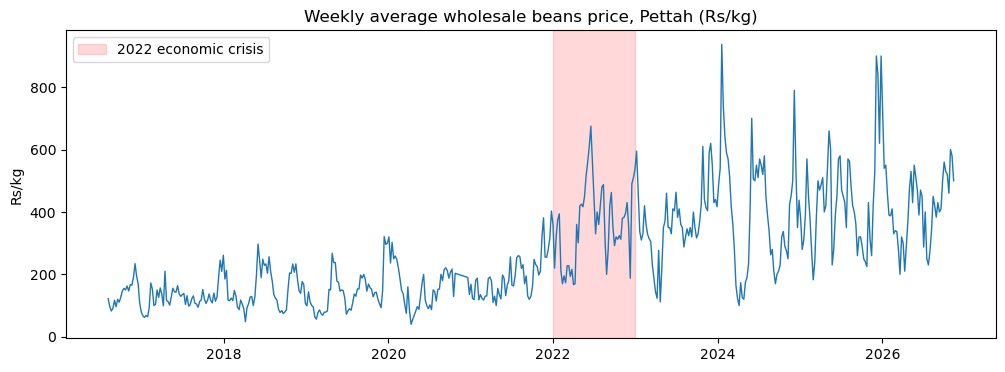

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(weekly.index, weekly["beans_pettah"], linewidth=1)
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2022-12-31"),
           alpha=0.15, color="red", label="2022 economic crisis")
ax.set_title("Weekly average wholesale beans price, Pettah (Rs/kg)")
ax.set_ylabel("Rs/kg")
ax.legend()
plt.show()

**What this shows:** prices averaged about Rs 130-160 in 2016-2019, rose in 2021 (Rs 194), then jumped in 2022 (Rs 360) and stayed high (Rs 367 in 2023, Rs 396 in 2024, Rs 433 in 2025). The highest week was 19 January 2024, at about Rs 938.

Prices more than doubled after the 2022 economic crisis and never returned to earlier levels. Tree models such as Random Forest and XGBoost cannot predict values higher than anything in their training data, so instead of the price itself, **the target will be the percentage change in price** (Step 3).

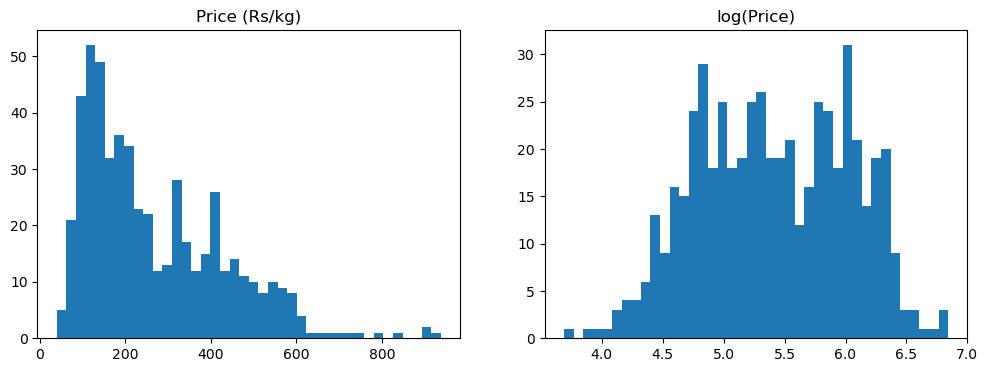

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(weekly["beans_pettah"], bins=40)
axes[0].set_title("Price (Rs/kg)")
axes[1].hist(np.log(weekly["beans_pettah"]), bins=40)
axes[1].set_title("log(Price)")
plt.show()

**What this shows:** the price distribution (left) is right-skewed, with a long tail of expensive weeks. After taking the log (right), it is much more balanced. Prices move in percentages (a Rs 50 rise matters far more at Rs 100 than at Rs 900), and the log treats a 10% rise the same at any price level. This supports using the change in log price as the target.

The cleaned weekly data is saved so later steps can start from it.

In [9]:
weekly.to_csv("dataset/weekly_clean.csv")
weekly.tail()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing
date,,,,,
2026-10-16,520.0,375.0,218.0,420.0,0
2026-10-23,460.0,392.0,206.0,410.0,0
2026-10-30,600.0,459.0,340.0,490.0,0
2026-11-06,580.0,498.0,440.0,600.0,0
2026-11-13,500.0,409.0,540.0,620.0,0


## Step 2: Add rainfall from the growing areas

Heavy rain and floods in the upcountry growing areas damage crops and block transport, so less beans reach Pettah and the price rises. This step adds weekly rainfall for the two main beans-growing districts, **Nuwara Eliya** and **Badulla**, to test that idea and to use rainfall as a feature.

In [14]:
weekly = pd.read_csv("dataset/weekly_clean.csv", index_col="date", parse_dates=True)
print(weekly.shape)
weekly.head(3)

(537, 5)


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing
date,,,,,
2016-08-05,122.0,146.0,100.0,70.00,0
2016-08-12,97.0,147.0,82.0,65.00,0
2016-08-19,82.5,125.0,85.0,71.25,0


### Downloading daily rainfall

Rainfall comes from **Open-Meteo**'s historical weather API (free, no sign-up), which provides daily rainfall in mm derived from ERA5, a global weather dataset from the EU's Copernicus programme. These are model estimates for each location, not rain-gauge readings.
- The download starts in July 2016, a month before the price data, so the first weeks of prices can still have rainfall from earlier weeks.
- It ends on 13 November 2026, the last full week of price data.
- The daily data is saved to `rain_daily.csv`, so the project works offline and can be rerun without downloading again.

In [15]:
import requests

def get_rain(lat, lon, name):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": lat,
        "longitude": lon,
        "start_date": "2016-07-01",
        "end_date": "2026-11-13",
        "daily": "precipitation_sum",
        "timezone": "Asia/Colombo",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    d = r.json()["daily"]
    return pd.Series(d["precipitation_sum"], index=pd.to_datetime(d["time"]), name=name)

rain = pd.concat([
    get_rain(6.9497, 80.7891, "rain_nuwaraeliya"),
    get_rain(6.9934, 81.0550, "rain_badulla"),
], axis=1)
rain.index.name = "date"

rain.to_csv("dataset/rain_daily.csv")
print(rain.shape)
rain.describe().round(1)

(3788, 2)


,rain_nuwaraeliya,rain_badulla
count,3788.0,3788.0
mean,5.3,6.4
std,9.4,12.4
min,0.0,0.0
25%,0.6,0.3
50%,2.3,2.1
75%,5.9,8.1
max,193.8,265.0


In [23]:
print(rain.isna().sum())
rain.tail()

rain_nuwaraeliya    0
rain_badulla        0
dtype: int64


,rain_nuwaraeliya,rain_badulla
date,,
2026-11-09,8.9,25.7
2026-11-10,21.3,13.4
2026-11-11,15.4,28.7
2026-11-12,15.4,35.6
2026-11-13,2.2,0.6


**Result:** there are no missing days for either location. The next cell (`fillna(0)`) is kept only as a safety step in case a rerun returns missing recent days; it changes nothing here.

In [17]:
rain = rain.fillna(0)

### Weekly rainfall totals

Daily rain is summed (not averaged) per week, because the total amount that fell is what affects crops and roads. The weeks end on Friday (`W-FRI`), exactly matching the price weeks.

In [18]:
rain_weekly = rain.resample("W-FRI").sum()
rain_weekly.head()

,rain_nuwaraeliya,rain_badulla
date,,
2016-07-01,4.1,0.3
2016-07-08,10.1,0.5
2016-07-15,65.3,20.3
2016-07-22,21.9,8.9
2016-07-29,86.0,76.5


In [19]:
data2 = weekly.join(rain_weekly, how="left")
print(data2.shape)
print(data2.isna().sum())
data2.head()

(537, 7)
beans_pettah        0
beans_dambulla      0
carrot_pettah       0
cabbage_pettah      0
was_missing         0
rain_nuwaraeliya    0
rain_badulla        0
dtype: int64


,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing,rain_nuwaraeliya,rain_badulla
date,,,,,,,
2016-08-05,122.0,146.0,100.0,70.00,0,18.8,15.6
2016-08-12,97.0,147.0,82.0,65.00,0,17.7,0.9
2016-08-19,82.5,125.0,85.0,71.25,0,30.5,0.4
2016-08-26,91.0,111.0,80.0,65.00,0,47.9,13.1
2016-09-02,117.0,123.0,72.0,61.00,0,31.7,5.8


**Result:** rainfall joined to all 537 price weeks with no missing values (7 columns: 4 prices, `was_missing` and 2 rainfall columns). `how="left"` keeps every price week.

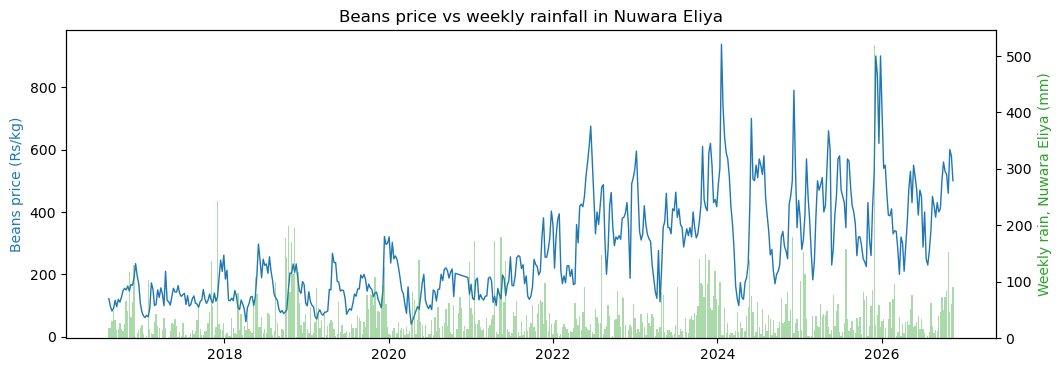

In [20]:
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(data2.index, data2["beans_pettah"], color="tab:blue", linewidth=1)
ax1.set_ylabel("Beans price (Rs/kg)", color="tab:blue")

ax2 = ax1.twinx()
ax2.bar(data2.index, data2["rain_nuwaraeliya"], width=6, color="tab:green", alpha=0.4)
ax2.set_ylabel("Weekly rain, Nuwara Eliya (mm)", color="tab:green")

ax1.set_title("Beans price vs weekly rainfall in Nuwara Eliya")
plt.show()

**What the chart shows:** rain is heaviest from October to December and in May (the two monsoons). Some of the biggest price jumps come right after very wet weeks, for example December 2019 (+117% after a 94 mm week in Nuwara Eliya) and late October 2025 (+91% after 75 mm). But several of the largest jumps fall in **April**, around Avurudu, after ordinary rainfall (2017, 2018, 2022, 2023). That suggests festival demand and holiday supply gaps also drive prices, not rain alone, so a festival feature is needed too.

### Does past rain relate to price changes?

The weekly % change in price is compared with rainfall from 0 to 4 weeks earlier.

In [21]:
data2["beans_change"] = np.log(data2["beans_pettah"]).diff()

for lag in range(0, 5):
    c1 = data2["beans_change"].corr(data2["rain_nuwaraeliya"].shift(lag))
    c2 = data2["beans_change"].corr(data2["rain_badulla"].shift(lag))
    print(f"rain {lag} week(s) earlier:  Nuwara Eliya {c1:.3f}   Badulla {c2:.3f}")

rain 0 week(s) earlier:  Nuwara Eliya 0.087   Badulla 0.050
rain 1 week(s) earlier:  Nuwara Eliya 0.324   Badulla 0.262
rain 2 week(s) earlier:  Nuwara Eliya 0.091   Badulla 0.068
rain 3 week(s) earlier:  Nuwara Eliya -0.139   Badulla -0.160
rain 4 week(s) earlier:  Nuwara Eliya -0.032   Badulla -0.046


**What the correlations show:** Rain one week earlier has the strongest link to price changes (r = 0.32 for Nuwara Eliya, 0.26 for Badulla): heavy rain in the growing areas is followed by a price rise in Colombo about a week later. After three weeks the relationship turns negative (r ≈ −0.15), suggesting prices fall back once supply recovers. Nuwara Eliya is more strongly related than Badulla at every lag. Based on this, I will use rainfall lagged by 1–3 weeks as features in Step 3.

The temporary `beans_change` column is dropped (Step 3 builds the target properly), and the combined weekly data is saved.

In [22]:
data2 = data2.drop(columns="beans_change")
data2.to_csv("dataset/weekly_with_rain.csv")
data2.tail()

,beans_pettah,beans_dambulla,carrot_pettah,cabbage_pettah,was_missing,rain_nuwaraeliya,rain_badulla
date,,,,,,,
2026-10-16,520.0,375.0,218.0,420.0,0,84.6,127.0
2026-10-23,460.0,392.0,206.0,410.0,0,153.3,98.7
2026-10-30,600.0,459.0,340.0,490.0,0,45.9,42.8
2026-11-06,580.0,498.0,440.0,600.0,0,60.7,74.6
2026-11-13,500.0,409.0,540.0,620.0,0,90.6,136.9


## Step 3: Build the target and features

**Rule for this step:** every feature must be something already known at the end of the current week. Only the target is allowed to look at next week; anything else that does is data leakage.

In [24]:
df = pd.read_csv("dataset/weekly_with_rain.csv", index_col="date", parse_dates=True)
logp = np.log(df["beans_pettah"])
feat = pd.DataFrame(index=df.index)
df.shape

(537, 7)

### Target: next week's % change in price

`shift(-1)` brings next week's log price into this week's row, so the target is log(next price) − log(this price), roughly next week's % change. I predict the change rather than the price because prices more than doubled after 2022, and tree models cannot predict values higher than anything in their training data. A % change looks the same before and after 2022.

In [25]:
feat["target"] = logp.shift(-1) - logp

### Features from beans' own recent price moves

- `chg_1` to `chg_4`: this week's and the previous three weeks' changes (recent momentum). `shift(k)` only looks back.
- `gap_ma4`: how far the price is above or below its 4-week average. Stretched prices tend to fall back (mean reversion).
- `vol_4`: how jumpy prices have been over the last 4 weeks.

In [26]:
feat["chg_1"] = logp.diff()                      # this week's change
feat["chg_2"] = feat["chg_1"].shift(1)           # last week's change
feat["chg_3"] = feat["chg_1"].shift(2)           # 2 weeks ago
feat["chg_4"] = feat["chg_1"].shift(3)           # 3 weeks ago
feat["gap_ma4"] = logp - logp.rolling(4).mean()  # distance from 4-week average
feat["vol_4"] = feat["chg_1"].rolling(4).std()   # recent volatility

### Features from other markets and vegetables

- `dambulla_gap`: Dambulla vs Pettah price. Traders move stock until the two markets meet again, so the gap hints at where Pettah is heading.
- `dambulla_chg`: Dambulla is closer to the farms, so its price often moves first.
- `carrot_chg`, `cabbage_chg`: grown in the same upcountry areas and carried on the same trucks, so they react to the same weather and transport problems.

Changes (not raw prices) keep everything on the same % scale before and after 2022.

In [27]:
feat["dambulla_gap"] = np.log(df["beans_dambulla"]) - logp
feat["dambulla_chg"] = np.log(df["beans_dambulla"]).diff()
feat["carrot_chg"]   = np.log(df["carrot_pettah"]).diff()
feat["cabbage_chg"]  = np.log(df["cabbage_pettah"]).diff()

### Rainfall features

Step 2 showed rain affects price 1-3 weeks later. Because the target is next week's change:
- `rain_*_0` (this week's rain) is rain 1 week before the target week, the strongest link (r = 0.32)
- `rain_*_1` (last week's rain) is 2 weeks before
- `rain_*_2` (rain 2 weeks ago) is 3 weeks before, where the link turned negative

So these lags come directly from the Step 2 analysis. `ne` = Nuwara Eliya, `bd` = Badulla.

In [28]:
for name, col in [("ne", "rain_nuwaraeliya"), ("bd", "rain_badulla")]:
    feat[f"rain_{name}_0"] = df[col]            # rain this week
    feat[f"rain_{name}_1"] = df[col].shift(1)   # rain last week
    feat[f"rain_{name}_2"] = df[col].shift(2)   # rain 2 weeks ago

### Calendar features

These use **next** week's month. That is not leakage: the calendar is known in advance, unlike next week's price or rain.
- `month_sin`, `month_cos` put the months on a circle, so December and January are neighbours (as 12 and 1 they would look far apart).
- `avurudu` (April) and `december` flag festival months, when vegetable demand rises.

In [29]:
next_week = df.index + pd.Timedelta(days=7)
feat["month_sin"] = np.sin(2 * np.pi * next_week.month / 12)
feat["month_cos"] = np.cos(2 * np.pi * next_week.month / 12)
feat["avurudu"]   = (next_week.month == 4).astype(int)
feat["december"]  = (next_week.month == 12).astype(int)

### Keep the real prices and remove incomplete rows

`price_now` and `price_next` are **not** features. They are kept only to turn predicted % changes back into Rs/kg for reporting. `dropna()` removes the first few weeks (no history yet for the lags and rolling windows) and the last week (no next week, so no target).

In [30]:
feat["price_now"]  = df["beans_pettah"]
feat["price_next"] = df["beans_pettah"].shift(-1)

print(feat.isna().sum().sum(), "missing values before dropna")
feat = feat.dropna()
print(feat.shape, feat.index.min().date(), "to", feat.index.max().date())

28 missing values before dropna
(532, 23) 2016-09-02 to 2026-11-06


### Time-based split

The data is split by date, never randomly. A random split would let the model learn from 2025 and be tested on 2020, which uses the future and gives scores that are too good.
- **Train** (2016-2023): models learn from this. It includes the 2022 crisis.
- **Validation** (2024): used to tune settings.
- **Test** (2025 to Nov 2026): used only once, at the end, for the final honest score.

In [31]:
feature_cols = [c for c in feat.columns if c not in ["target", "price_now", "price_next"]]

train = feat[feat.index <= "2023-12-31"]
val   = feat[(feat.index > "2023-12-31") & (feat.index <= "2024-12-31")]
test  = feat[feat.index > "2024-12-31"]

print("features:", len(feature_cols))
print("train:", len(train), " val:", len(val), " test:", len(test))

features: 20
train: 383  val: 52  test: 97


### Sanity check: how each feature relates to the target

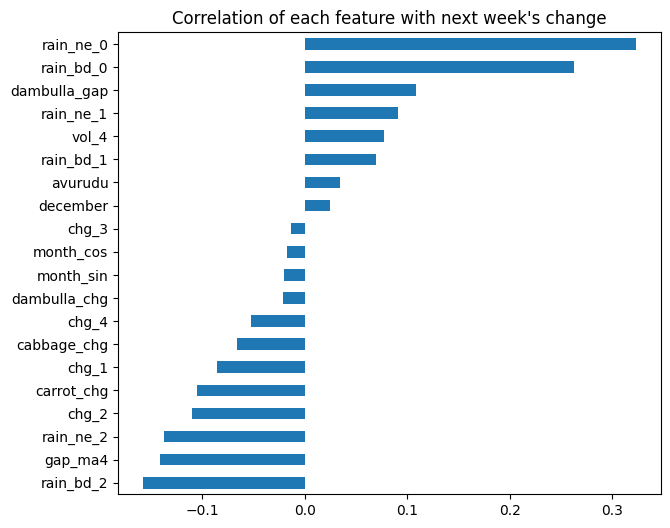

rain_bd_2      -0.158
gap_ma4        -0.141
rain_ne_2      -0.138
chg_2          -0.110
carrot_chg     -0.105
chg_1          -0.085
cabbage_chg    -0.066
chg_4          -0.053
dambulla_chg   -0.021
month_sin      -0.021
month_cos      -0.017
chg_3          -0.014
december        0.025
avurudu         0.035
rain_bd_1       0.070
vol_4           0.077
rain_ne_1       0.091
dambulla_gap    0.108
rain_bd_0       0.262
rain_ne_0       0.323
dtype: float64

In [32]:
corr = feat[feature_cols].corrwith(feat["target"]).sort_values()
corr.plot(kind="barh", figsize=(7, 6), title="Correlation of each feature with next week's change")
plt.show()
corr.round(3)

**What this shows:**
- This week's rain is the strongest link (`rain_ne_0` +0.32, `rain_bd_0` +0.26): heavy rain in the growing areas is followed by a price rise the next week.
- Rain from 2 weeks ago is negative (about −0.14 to −0.16): roughly 3 weeks after the rain, prices fall back as supply recovers.
- `gap_ma4` is negative (−0.14): when the price is above its 4-week average, it tends to fall the next week (mean reversion).
- `chg_1` and `chg_2` are negative: a rise is often followed by a partial fall.
- The calendar features are close to zero. Their effect is not a straight line, so tree models may still use them; feature importance in Step 6 will show whether they do.

Correlation only measures straight-line relationships, so this is a check, not a final answer.

In [33]:
feat.to_csv("dataset/features.csv")

## Step 4: Baseline models

Before building ensembles, I need simple baselines: scores that every ensemble has to beat. If an ensemble cannot beat them, it adds nothing.

1. **Naive:** next week's price = this week's price (predicted change = 0).
2. **Seasonal naive:** next week changes by the same % as the same week last year.
3. **Linear regression:** a straight-line combination of the 20 features.
4. **Single decision tree:** the building block that bagging and boosting are made of.

In [34]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import time

feat = pd.read_csv("dataset/features.csv", index_col="date", parse_dates=True)
feature_cols = [c for c in feat.columns if c not in ["target", "price_now", "price_next"]]

train = feat[feat.index <= "2023-12-31"]
val   = feat[(feat.index > "2023-12-31") & (feat.index <= "2024-12-31")]
test  = feat[feat.index > "2024-12-31"]

X_train, y_train = train[feature_cols], train["target"]
X_val,   y_val   = val[feature_cols],   val["target"]
X_test,  y_test  = test[feature_cols],  test["target"]
print(X_train.shape, X_val.shape, X_test.shape)

(383, 20) (52, 20) (97, 20)


### How every model is scored

Models predict next week's % change. To report results in a way anyone understands, each predicted change is turned back into a price: `predicted price = this week's price × e^(predicted change)`, and compared with the real price next week.

- **RMSE (Rs/kg):** the main metric. It squares errors before averaging, so it punishes big misses (price spikes), which hurt traders most.
- **MAE (Rs/kg):** the average size of the error, easy to explain ("off by Rs 65/kg on average").
- **R² (on the % change):** the share of the week-to-week change the model explains. 0 means no better than predicting "no change"; below 0 means worse.
- **Train, validation and test** are scored separately. The test set is reported for every model but **never used to choose settings**, so the comparison stays honest.

Every result goes into one `results` list, which becomes the final comparison table in Step 9.

In [35]:
results = []

def score(part, pred_change):
    pred_price = part["price_now"] * np.exp(pred_change)
    return {
        "rmse": np.sqrt(mean_squared_error(part["price_next"], pred_price)),
        "mae": mean_absolute_error(part["price_next"], pred_price),
        "r2": r2_score(part["target"], pred_change),
    }

def add_result(name, pred_train, pred_val, pred_test, train_time=0.0):
    tr, va, te = score(train, pred_train), score(val, pred_val), score(test, pred_test)
    results.append({
        "model": name,
        "train_rmse": tr["rmse"], "val_rmse": va["rmse"], "test_rmse": te["rmse"],
        "test_mae": te["mae"], "train_r2": tr["r2"], "test_r2": te["r2"],
        "train_time_s": train_time,
    })

### Baselines 1 and 2: naive and seasonal naive

Neither needs training. The naive model always predicts a change of 0. The seasonal model copies the % change from the same week one year earlier; for the first year there is no previous year, so it falls back to 0 (the naive guess).

In [36]:
raw = pd.read_csv("dataset/weekly_with_rain.csv", index_col="date", parse_dates=True)
logp_all = np.log(raw["beans_pettah"])
seasonal = (logp_all.shift(51) - logp_all.shift(52)).reindex(feat.index).fillna(0)

add_result("Naive (no change)", np.zeros(len(train)), np.zeros(len(val)), np.zeros(len(test)))
add_result("Seasonal naive", seasonal.loc[train.index], seasonal.loc[val.index], seasonal.loc[test.index])

### Baseline 3: linear regression

Features are scaled with `StandardScaler` (mean 0, standard deviation 1) because rainfall is in mm (0-300) while price changes are small decimals; scaling puts them on the same footing and makes the coefficients comparable. The scaler sits inside a `Pipeline`, so it learns the mean and standard deviation from the **training data only** and never sees validation or test data.

In [37]:
t0 = time.perf_counter()
linreg = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
t = time.perf_counter() - t0

add_result("Linear regression", linreg.predict(X_train), linreg.predict(X_val), linreg.predict(X_test), t)

### Baseline 4: a single decision tree

Default settings, with no limit on depth, to see what one unrestricted tree does. Trees do not need scaling: they split on thresholds ("is rain above 60 mm?"), not distances.

In [38]:
t0 = time.perf_counter()
tree = DecisionTreeRegressor(random_state=42).fit(X_train, y_train)
t = time.perf_counter() - t0

add_result("Decision tree", tree.predict(X_train), tree.predict(X_val), tree.predict(X_test), t)
print("depth:", tree.get_depth(), " leaves:", tree.get_n_leaves(), " training rows:", len(X_train))

depth: 26  leaves: 383  training rows: 383


### Baseline results

In [39]:
res = pd.DataFrame(results).set_index("model")
res.round(3)

,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
Seasonal naive,95.925,140.071,158.474,113.162,-0.704,-1.177,0.000
Linear regression,49.463,103.360,97.201,65.589,0.200,0.326,0.007
Decision tree,0.000,136.520,132.041,99.220,1.000,-0.259,0.010


**What the baselines show:**
- **Naive is a tough benchmark:** on the test set, "no change" is off by about Rs 107/kg (RMSE). Prices often stay near last week's level, so this is hard to beat.
- **Seasonal naive is much worse** (test RMSE about Rs 158). Copying last year's change does not work: price spikes depend on that year's rain and supply, not on a fixed yearly calendar.
- **Linear regression beats naive:** test RMSE about Rs 97 and MAE about Rs 66 (vs Rs 82 for naive), explaining about a third of the weekly change (R² ≈ 0.33). So the features carry real information.
- **The single decision tree overfits badly:** its training error is 0, but its test RMSE (about Rs 132) is worse than naive. It grew to depth 26 with 383 leaves, one leaf for every training week, so it **memorised** the training data instead of learning patterns. This high variance is exactly what bagging (Step 5) is designed to fix.
- **Why training RMSE is lower for every model:** prices in the training years (2016-2023) were mostly much lower than in 2024-2026, so the same % error is fewer rupees. To judge overfitting fairly, compare R² (scale-free) or compare each model with the naive baseline in the same period.

**The bar to beat:** test RMSE ≈ Rs 97 (linear regression) and ≈ Rs 107 (naive).

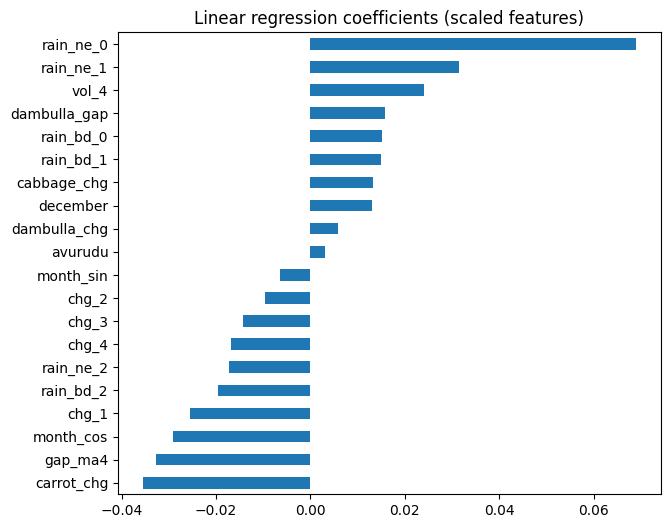

In [40]:
coef = pd.Series(linreg[-1].coef_, index=feature_cols).sort_values()
coef.plot(kind="barh", figsize=(7, 6), title="Linear regression coefficients (scaled features)")
plt.show()

**What the coefficients show:** because the features are scaled, larger bars mean stronger effects. This week's Nuwara Eliya rain (`rain_ne_0`) has by far the largest positive effect, while `carrot_chg`, `gap_ma4` and `chg_1` are negative: when prices have just risen or are above their recent average, they tend to fall back next week (mean reversion). This matches the correlations in Step 3.

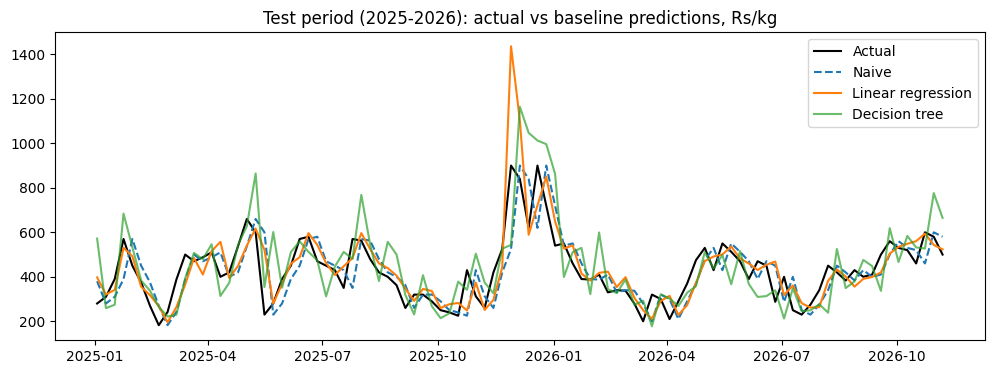

In [41]:
pred_price = lambda m: test["price_now"] * np.exp(m.predict(X_test))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(test.index, test["price_next"], color="black", linewidth=1.5, label="Actual")
ax.plot(test.index, test["price_now"], linestyle="--", label="Naive")
ax.plot(test.index, pred_price(linreg), label="Linear regression")
ax.plot(test.index, pred_price(tree), alpha=0.7, label="Decision tree")
ax.set_title("Test period (2025-2026): actual vs baseline predictions, Rs/kg")
ax.legend()
plt.show()

**What the chart shows:** the naive line is simply the actual price shifted one week later, so it is always one step behind every spike and every fall. Linear regression follows the actual price more closely. The decision tree jumps around erratically, because each prediction copies a single memorised training week.

In [42]:
res.to_csv("results/results_step4_baselines.csv")

## Step 5: Bagging

The single decision tree memorised the training data (training error 0, test RMSE ≈ Rs 132): it has **high variance**, meaning small changes in the training data produce a very different tree. **Bagging** (bootstrap aggregating) fixes this:
1. draw many **bootstrap samples**: random samples of the training weeks, with replacement, each the same size as the training set;
2. grow one full tree on each sample;
3. **average** all the trees' predictions.

Each tree still overfits, but they overfit in *different* ways, so averaging cancels much of the noise.

**Out-of-bag (OOB) score:** each bootstrap sample leaves out about 37% of the weeks. Each week can be predicted by only the trees that never saw it, giving a free validation score without a separate dataset (`oob_score=True`).

In [43]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance

oob = {}   # OOB predictions in Rs, per model

def oob_rmse(model):
    pred_price = train["price_now"] * np.exp(model.oob_prediction_)
    return np.sqrt(mean_squared_error(train["price_next"], pred_price))

### Bagging with decision trees

300 full-depth trees, each trained on its own bootstrap sample of the 383 training weeks.

In [44]:
t0 = time.perf_counter()
bag = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=300,
                       oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0

add_result("Bagging (300 trees)", bag.predict(X_train), bag.predict(X_val), bag.predict(X_test), t)
oob["Bagging (300 trees)"] = (bag.oob_score_, oob_rmse(bag))

### Random Forest

Random Forest is bagging plus one extra idea: at each split, a tree may only choose from a **random subset of the features**. This stops every tree from splitting on the same strongest feature, so the trees become less alike (decorrelated), and averaging less-alike trees cancels more noise.

`max_features` controls the subset size. In scikit-learn the regression default is 1.0 (all features), which makes it almost identical to bagging, so two versions are trained:
- **Random Forest (all features)**: the scikit-learn default;
- **Random Forest (sqrt)**: √20 ≈ 4 random features per split, the classic Random Forest setting.

In [45]:
t0 = time.perf_counter()
rf = RandomForestRegressor(n_estimators=500, oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Random Forest (all features)", rf.predict(X_train), rf.predict(X_val), rf.predict(X_test), t)
oob["Random Forest (all features)"] = (rf.oob_score_, oob_rmse(rf))

t0 = time.perf_counter()
rf_sqrt = RandomForestRegressor(n_estimators=500, max_features="sqrt", oob_score=True,
                                random_state=42, n_jobs=-1).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Random Forest (sqrt)", rf_sqrt.predict(X_train), rf_sqrt.predict(X_val), rf_sqrt.predict(X_test), t)
oob["Random Forest (sqrt)"] = (rf_sqrt.oob_score_, oob_rmse(rf_sqrt))

### Results so far

In [46]:
res = pd.DataFrame(results).set_index("model")
res.round(3)

,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
Seasonal naive,95.925,140.071,158.474,113.162,-0.704,-1.177,0.000
Linear regression,49.463,103.360,97.201,65.589,0.200,0.326,0.014
Decision tree,0.000,136.520,132.041,99.220,1.000,-0.259,0.006
Bagging (300 trees),19.896,95.740,87.974,69.926,0.873,0.319,2.808
Random Forest (all features),20.224,93.923,88.060,70.048,0.871,0.318,1.260
Random Forest (sqrt),19.891,97.290,90.143,69.805,0.877,0.303,0.609


**What this shows:**
- **Bagging fixes the single tree's overfitting:** test RMSE falls from about Rs 132 (one tree) to about Rs 88 (300 bagged trees). Same kind of tree, same data; the only difference is averaging.
- **All bagging models beat both baselines on RMSE:** about Rs 88-90, compared with Rs 97 for linear regression and Rs 107 for naive.
- **But not on MAE:** linear regression's average error (about Rs 66) is still slightly lower than the forests' (about Rs 70). RMSE punishes big misses, so the forests are better at the large price spikes but slightly worse on ordinary weeks. Which model is "best" depends on whether big misses or typical misses matter more; for traders, big spikes are the costly ones, so RMSE stays the main metric.
- **The trees still memorise:** training RMSE is only about Rs 20 (training R² ≈ 0.87, test R² ≈ 0.3). Each full-depth tree overfits, but averaging stops this from hurting the test score.
- **Random feature subsets (sqrt) did not help here:** test RMSE about Rs 90 vs Rs 88 with all features. With only 20 features and one dominant feature (this week's Nuwara Eliya rain), forcing most splits to ignore it costs more than decorrelating the trees gains. Random Forest's trick helps most when there are many useful features.
- **Training time** stays small (around a second or less), because the dataset is small.

### What the out-of-bag (OOB) score showed

The OOB score is compared with the real validation and test scores to see whether it was a good estimate.

In [47]:
oob_table = pd.DataFrame(oob, index=["OOB R²", "OOB RMSE (Rs)"]).T
oob_table["Test R²"] = res.loc[oob_table.index, "test_r2"]
print("Naive RMSE on the same training weeks: Rs", round(res.loc["Naive (no change)", "train_rmse"], 1))
oob_table.round(3)

Naive RMSE on the same training weeks: Rs 55.1


,OOB R²,OOB RMSE (Rs),Test R²
Bagging (300 trees),0.045,52.954,0.319
Random Forest (all features),0.040,53.223,0.318
Random Forest (sqrt),0.087,52.190,0.303


In [48]:
rf_oob = pd.Series(rf.oob_prediction_, index=train.index)
for start, end in [("2016", "2019"), ("2020", "2021"), ("2022", "2023")]:
    part = train.loc[start:end]
    print(f"{start}-{end}: OOB R² = {r2_score(part['target'], rf_oob.loc[start:end]):.2f}")

2016-2019: OOB R² = -0.01
2020-2021: OOB R² = 0.03
2022-2023: OOB R² = 0.13


**What the OOB score showed:** I expected the OOB score to be **too optimistic**, because bootstrap samples mix weeks from different years, so a tree can learn from 2023 and be scored on 2018 (using the future). The opposite happened: OOB R² is only about 0.04-0.09, much **lower** than the test R² (about 0.3), and OOB RMSE (about Rs 52-53) is only slightly better than naive on the same weeks (Rs 55).

Two reasons, both visible in the data:
1. **Little leakage in this target:** the target is the week-to-week % change, which has almost no long-term memory. Seeing a 2023 week tells the model little about a 2018 week, so mixing years leaks very little.
2. **The relationships got stronger over time:** split by period, OOB R² is about −0.01 in 2016-2019, 0.03 in 2020-2021 and 0.13 in 2022-2023. Before 2022 the features explain almost nothing; afterwards, with tighter supply and higher prices, rain and market signals matter more. The test period (2025-2026) is like the later years, so it scores higher.

**Lesson:** the OOB score assumes all training weeks behave the same way. When the relationship changes over time, a time-ordered validation set is the more trustworthy guide, which is why tuning (Step 7) uses `TimeSeriesSplit`.

### How many trees are enough?

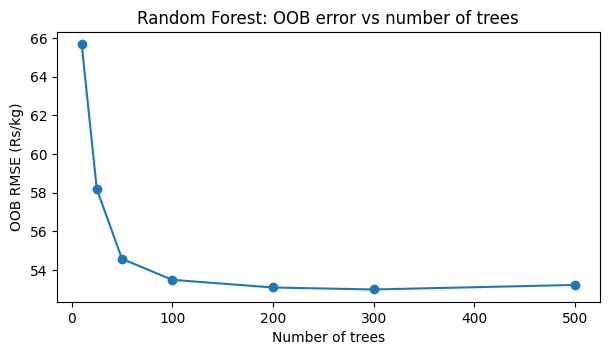

,trees,oob_rmse
0,10,65.7
1,25,58.2
2,50,54.6
3,100,53.5
4,200,53.1
5,300,53.0
6,500,53.2


In [49]:
curve = []
rf_grow = RandomForestRegressor(n_estimators=10, oob_score=True, warm_start=True, random_state=42, n_jobs=-1)
for n in [10, 25, 50, 100, 200, 300, 500]:
    rf_grow.set_params(n_estimators=n)
    rf_grow.fit(X_train, y_train)
    curve.append((n, oob_rmse(rf_grow)))
curve = pd.DataFrame(curve, columns=["trees", "oob_rmse"])

plt.figure(figsize=(7, 3.5))
plt.plot(curve["trees"], curve["oob_rmse"], marker="o")
plt.xlabel("Number of trees")
plt.ylabel("OOB RMSE (Rs/kg)")
plt.title("Random Forest: OOB error vs number of trees")
plt.show()
curve.round(1)

**What this shows:** the OOB error drops quickly from 10 to about 100 trees (about Rs 66 to Rs 53) and then stays flat. Adding trees reduces variance up to a point; after that, extra trees only cost time. Importantly, **more trees never make a Random Forest overfit**: the curve does not rise again. 500 trees is safely past the flat point.

### Feature importance

Two ways to measure it:
- **Impurity-based importance** (built into the forest): how much each feature reduced error inside the training data. It is fast but measured on data the trees have already seen, and it favours features with many different values.
- **Permutation importance** (on the 2024 validation data): shuffle one feature and measure how much worse the predictions get. If shuffling it hurts, the model really relies on it for **unseen** weeks.

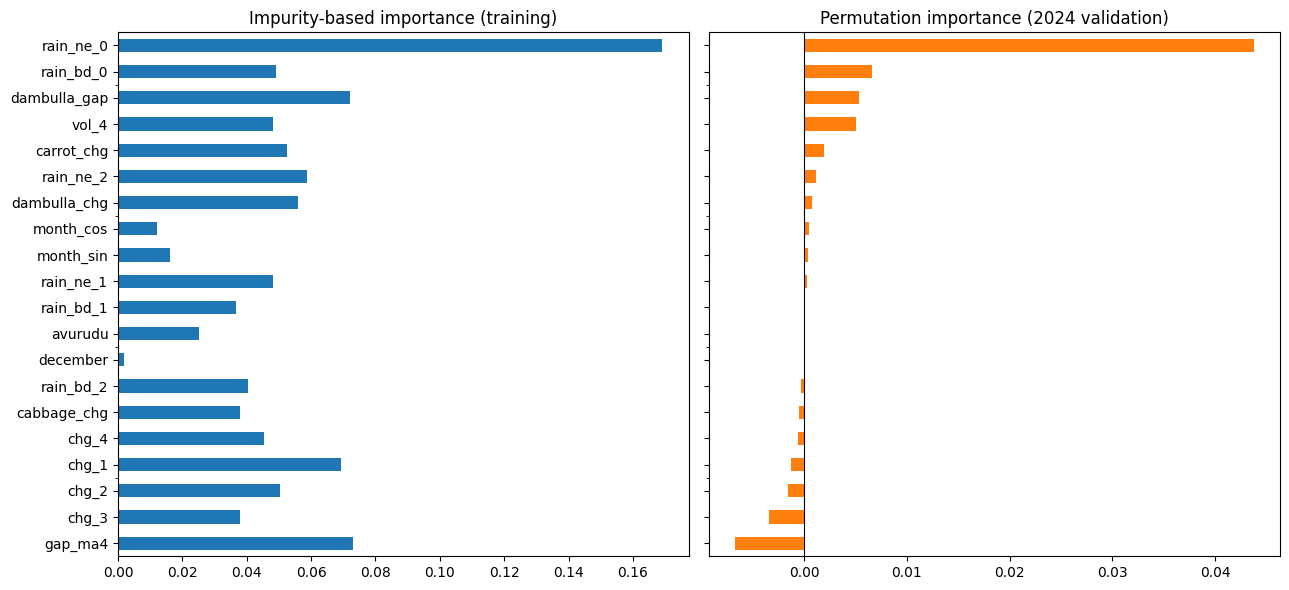

In [50]:
imp = pd.DataFrame({
    "impurity (training)": pd.Series(rf.feature_importances_, index=feature_cols),
    "permutation (validation)": pd.Series(
        permutation_importance(rf, X_val, y_val, n_repeats=20, random_state=42,
                               scoring="neg_root_mean_squared_error", n_jobs=-1).importances_mean,
        index=feature_cols),
}).sort_values("permutation (validation)")

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
imp["impurity (training)"].plot(kind="barh", ax=axes[0], title="Impurity-based importance (training)")
imp["permutation (validation)"].plot(kind="barh", ax=axes[1], color="tab:orange",
                                     title="Permutation importance (2024 validation)")
axes[1].axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

**What the importances show:**
- **This week's Nuwara Eliya rain (`rain_ne_0`) is the most important feature by both measures**, far ahead of the rest on validation data. This matches Step 2 (rain one week before the price change) and the linear-regression coefficients: rain in the growing areas is the strongest signal for next week's price.
- **Badulla rain, the Dambulla-Pettah price gap and recent volatility (`vol_4`)** also help on unseen weeks.
- **The two measures disagree on the price-history features** (`chg_1` to `chg_4`, `gap_ma4`). The forest uses them a lot inside the training data, but on 2024 data shuffling them slightly *improves* predictions (negative permutation importance). So the trees learned mean-reversion patterns from 2016-2023 that did not hold in 2024; this is part of why the training error (Rs 20) is so much lower than the validation error.
- **Calendar features matter little** on their own; festival effects partly show up through the price and rain features instead.

This is why permutation importance on held-out data is the more trustworthy measure.

In [51]:
res.to_csv("results/results_step5_bagging.csv")

## Step 6: Boosting

Bagging grows trees **independently** and averages them, which reduces **variance**. Boosting grows trees **one after another**: each new tree is trained on the errors the previous trees still make, so the model gradually fixes what it gets wrong. This reduces **bias** (underfitting), but because it keeps chasing errors, it can also start fitting noise, so it needs careful settings.

The three main settings:
- **`n_estimators`**: how many trees are added in sequence. Too few underfits; too many starts fitting noise.
- **`learning_rate`**: how much each new tree is allowed to correct. Smaller steps are more careful but need more trees.
- **`max_depth`**: how complex each tree is. Boosting works best with small, simple trees ("weak learners"), each fixing a little.

Four implementations are compared: scikit-learn's **Gradient Boosting**, **XGBoost**, **LightGBM** and **CatBoost**.

In [52]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)     # hide library version notices
warnings.filterwarnings("ignore", category=FutureWarning)

from sklearn.ensemble import GradientBoostingRegressor, BaggingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor, early_stopping
from catboost import CatBoostRegressor

def val_rmse_rs(pred_change):
    return score(val, pred_change)["rmse"]

### Learning rate vs number of trees

Gradient Boosting is trained with 600 trees at three learning rates, and the validation (2024) error is measured after every tree using `staged_predict`.

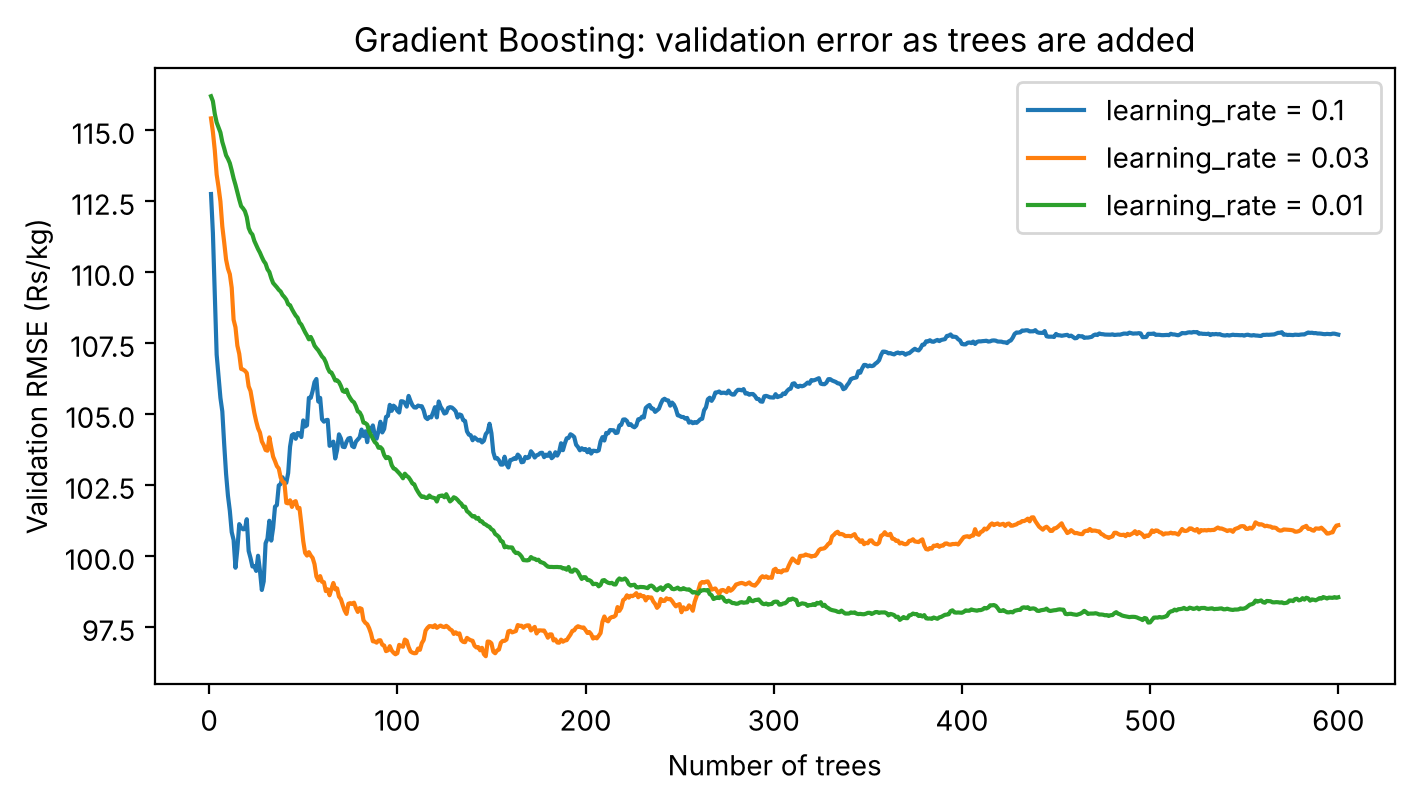

,best number of trees,best val RMSE,val RMSE at 600 trees
0.10,28.0,98.8,107.8
0.03,147.0,96.5,101.1
0.01,499.0,97.7,98.6


In [53]:
curves = {}
for lr in [0.1, 0.03, 0.01]:
    gb_lr = GradientBoostingRegressor(n_estimators=600, learning_rate=lr, max_depth=3,
                                      subsample=0.8, random_state=42).fit(X_train, y_train)
    curves[lr] = [val_rmse_rs(p) for p in gb_lr.staged_predict(X_val)]

plt.figure(figsize=(8, 4))
for lr, c in curves.items():
    plt.plot(range(1, 601), c, label=f"learning_rate = {lr}")
plt.xlabel("Number of trees")
plt.ylabel("Validation RMSE (Rs/kg)")
plt.title("Gradient Boosting: validation error as trees are added")
plt.legend()
plt.show()

pd.DataFrame({lr: {"best number of trees": int(np.argmin(c)) + 1, "best val RMSE": min(c), "val RMSE at 600 trees": c[-1]}
              for lr, c in curves.items()}).T.round(1)

**What this shows:**
- **learning_rate = 0.1** reaches its best validation error after only about 30 trees, then gets steadily **worse** as more trees are added (about Rs 99 → Rs 108): each big step starts fitting noise. This is boosting overfitting.
- **learning_rate = 0.03** reaches a slightly better best (about Rs 96-97) after about 150 trees and degrades much more slowly.
- **learning_rate = 0.01** needs about 500 trees to reach a similar level.

Smaller learning rates are more forgiving but slower. **0.03 is a good balance** and is used for all four models below. Unlike Random Forest (where more trees never hurt), boosting needs the number of trees **chosen carefully**.

### How deep should each tree be?

In [54]:
depth_rows = []
for d in [2, 3, 4, 6]:
    m = GradientBoostingRegressor(n_estimators=200, learning_rate=0.03, max_depth=d,
                                  subsample=0.8, random_state=42).fit(X_train, y_train)
    depth_rows.append({"max_depth": d,
                       "train RMSE": score(train, m.predict(X_train))["rmse"],
                       "val RMSE": val_rmse_rs(m.predict(X_val))})
pd.DataFrame(depth_rows).set_index("max_depth").round(1)

,train RMSE,val RMSE
max_depth,,
2,39.0,99.0
3,31.6,97.4
4,23.5,98.7
6,9.9,100.1


**What this shows:** deeper trees cut the **training** error sharply (about Rs 39 at depth 2 → Rs 10 at depth 6), but the **validation** error barely changes (about Rs 97-100, and slightly worse at depth 6). The extra depth only memorises the training weeks. **max_depth = 3** gives the best validation score with simple trees, so it is used below.

### Training the four boosting models

All four use `learning_rate = 0.03` and trees of depth 3. The number of trees is chosen by **early stopping**: trees are added up to a limit of 1,000, and training stops when the **2024 validation** error has not improved for 50 rounds. Early stopping uses the validation set, never the test set, so the test score stays honest.

`subsample = 0.8` trains each tree on a random 80% of the weeks, a small dose of bagging inside boosting that makes it less likely to fit noise.

In [55]:
n_trees = {}

# scikit-learn Gradient Boosting: find the best number of trees on validation, then refit
gb_search = GradientBoostingRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3,
                                      subsample=0.8, random_state=42).fit(X_train, y_train)
best_n = int(np.argmin([mean_squared_error(y_val, p) for p in gb_search.staged_predict(X_val)])) + 1
t0 = time.perf_counter()
gb = GradientBoostingRegressor(n_estimators=best_n, learning_rate=0.03, max_depth=3,
                               subsample=0.8, random_state=42).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("Gradient Boosting", gb.predict(X_train), gb.predict(X_val), gb.predict(X_test), t)
n_trees["Gradient Boosting"] = best_n

In [56]:
t0 = time.perf_counter()
xgb = XGBRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3, subsample=0.8,
                   colsample_bytree=0.8, early_stopping_rounds=50, random_state=42)
xgb.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
t = time.perf_counter() - t0
add_result("XGBoost", xgb.predict(X_train), xgb.predict(X_val), xgb.predict(X_test), t)
n_trees["XGBoost"] = xgb.best_iteration + 1

In [57]:
t0 = time.perf_counter()
lgbm = LGBMRegressor(n_estimators=1000, learning_rate=0.03, max_depth=3, num_leaves=8,
                     subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                     min_child_samples=10, random_state=42, verbose=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[early_stopping(50, verbose=False)])
t = time.perf_counter() - t0
add_result("LightGBM", lgbm.predict(X_train), lgbm.predict(X_val), lgbm.predict(X_test), t)
n_trees["LightGBM"] = lgbm.best_iteration_

In [58]:
t0 = time.perf_counter()
cat = CatBoostRegressor(iterations=1000, learning_rate=0.03, depth=3, random_seed=42, verbose=0,
                        od_type="Iter", od_wait=50, use_best_model=True)
cat.fit(X_train, y_train, eval_set=(X_val, y_val))
t = time.perf_counter() - t0
add_result("CatBoost", cat.predict(X_train), cat.predict(X_val), cat.predict(X_test), t)
n_trees["CatBoost"] = cat.get_best_iteration() + 1

### For comparison: XGBoost with its default settings

XGBoost's defaults are 100 trees of depth 6 with a learning rate of 0.3, much more aggressive than the settings above.

In [59]:
t0 = time.perf_counter()
xgb_default = XGBRegressor(random_state=42).fit(X_train, y_train)
t = time.perf_counter() - t0
add_result("XGBoost (default settings)", xgb_default.predict(X_train), xgb_default.predict(X_val), xgb_default.predict(X_test), t)

In [60]:
res = pd.DataFrame(results).set_index("model")
print("Trees chosen by early stopping:", n_trees)
res.round(3)

Trees chosen by early stopping: {'Gradient Boosting': 152, 'XGBoost': 121, 'LightGBM': 123, 'CatBoost': 233}


,train_rmse,val_rmse,test_rmse,test_mae,train_r2,test_r2,train_time_s
model,,,,,,,
Naive (no change),55.139,116.337,107.395,81.735,-0.000,-0.000,0.000
Seasonal naive,95.925,140.071,158.474,113.162,-0.704,-1.177,0.000
Linear regression,49.463,103.360,97.201,65.589,0.200,0.326,0.004
Decision tree,0.000,136.520,132.041,99.220,1.000,-0.259,0.008
Bagging (300 trees),19.896,95.740,87.974,69.926,0.873,0.319,1.768
Random Forest (all features),20.224,93.923,88.060,70.048,0.871,0.318,1.270
Random Forest (sqrt),19.891,97.290,90.143,69.805,0.877,0.303,0.609
Gradient Boosting,34.445,96.585,85.533,67.325,0.635,0.346,0.243
XGBoost,37.859,97.613,90.168,69.533,0.537,0.315,0.062


### Is the difference between models real? A check with different random seeds

Both Gradient Boosting (`subsample=0.8`) and bagging use randomness, so their scores change slightly with the random seed. Each is retrained with 10 different seeds (same settings) to see how much the test RMSE moves just by chance. This is only a check of variability, not used to choose any model.

In [61]:
seed_rows = []
for s in range(10):
    g = GradientBoostingRegressor(n_estimators=n_trees["Gradient Boosting"], learning_rate=0.03, max_depth=3,
                                  subsample=0.8, random_state=s).fit(X_train, y_train)
    b = BaggingRegressor(estimator=DecisionTreeRegressor(), n_estimators=300,
                         random_state=s, n_jobs=-1).fit(X_train, y_train)
    seed_rows.append({"seed": s, "Gradient Boosting": score(test, g.predict(X_test))["rmse"],
                      "Bagging": score(test, b.predict(X_test))["rmse"]})
seeds = pd.DataFrame(seed_rows).set_index("seed")
seeds.agg(["mean", "std", "min", "max"]).round(1)

,Gradient Boosting,Bagging
mean,87.7,88.1
std,1.2,0.5
min,86.4,87.3
max,89.6,89.4


**What this shows:**
- **With the main seed (42), Gradient Boosting has the best test RMSE so far: about Rs 85.5** (MAE about Rs 67, test R² about 0.35), ahead of bagging and Random Forest (about Rs 88).
- **But the seed check shows this is partly luck:** over 10 seeds, Gradient Boosting averages about Rs 87.7 (range about Rs 86-90) and bagging about Rs 88.1 (range about Rs 87-89). On average the two are **essentially tied**, and differences of 1-3 Rs between models are within random variation on 97 test weeks. Bagging is also more stable from seed to seed.
- **XGBoost, LightGBM and CatBoost** land at about Rs 90-92, slightly behind. They use extra regularisation that scikit-learn's Gradient Boosting does not (XGBoost and LightGBM also sample 80% of the features per tree; CatBoost uses symmetric trees and an L2 penalty), which makes them a little more cautious here. All boosting models still beat linear regression (Rs 97) and naive (Rs 107) on RMSE.
- **Why boosting did not clearly beat bagging:** boosting's strength is reducing bias by finding more and more detailed patterns. But week-to-week price changes are very noisy, and most of the learnable signal comes from a few strong features (mainly this week's Nuwara Eliya rain), which bagging already captures. Beyond that, there is mostly noise for boosting to chase.
- **Boosting overfits less than bagging, as configured:** training RMSE is about Rs 34-43 (training R² ≈ 0.4-0.6) versus Rs 20 (R² ≈ 0.87) for the bagged full-depth trees. Shallow trees, a small learning rate and early stopping keep it from memorising, yet the test score is about the same, which again suggests little extra signal is left.
- **Defaults overfit:** XGBoost with default settings memorised the training data (training RMSE ≈ Rs 0.2, R² ≈ 1.00) because of its deeper trees and large learning rate. Its test score happens to be similar, but a model that memorises its training data is fragile.
- **The four libraries behave similarly** on this small dataset (383 rows, numeric features only). Their speed and categorical-data advantages (LightGBM's leaf-wise growth, CatBoost's categorical handling) matter on much larger datasets.
- **Early stopping picked about 120-230 trees**, consistent with the learning-rate experiment.

The settings here were chosen on one validation year (2024). Step 7 tunes them more thoroughly with time-series cross-validation.

In [62]:
res.to_csv("results/results_step6_boosting.csv")